In [ ]:
# Notebook setup: load the same featured data and deterministic splits as the Python model scripts.
from pathlib import Path
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "Project_machine_notebook.ipynb").is_file():
    if (PROJECT_ROOT.parent / "Project_machine_notebook.ipynb").is_file():
        PROJECT_ROOT = PROJECT_ROOT.parent
    else:
        raise FileNotFoundError("Open/run this notebook with the project folder as the working directory.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT / "Datasets")
from Analysis.model_data import get_data
_df_featured = pd.read_csv("final_featured_dataset.csv")
feat_cols = [c for c in _df_featured.columns if c.startswith("roll")]
feat_cols += [c for c in ["streak", "days_rest", "opp_def_r5", "opp_xg_att_r5", "is_home"] if c in _df_featured]
feat_cols = list(dict.fromkeys(feat_cols))
df = _df_featured.copy()
X_train, X_test, y_train, y_test, feat_cols = get_data()
X_train_smote, _, y_train_smote, _, _ = get_data(balance=True)
X = df[feat_cols].to_numpy()
y = df["target"].to_numpy()
N_SPLITS, EARLY_STOP, SEED = 5, 75, 42
WINDOWS = [3, 5, 10]
LABEL_NAMES = {0: "Loss", 1: "Draw", 2: "Win"}



# XGBOOST


In [ ]:
# ------------- SAMPLE WEIGHT HELPERS -------------
from sklearn.model_selection import TimeSeriesSplit
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt, matplotlib.gridspec as gridspec
import xgboost as xgb
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, log_loss)


def sample_weights(y):
    classes, counts = np.unique(y, return_counts=True)
    freq = dict(zip(classes, counts))
    return np.array([len(y) / (len(classes) * freq[c]) for c in y])

# ------------- TIME‑SERIES CROSS‑VALIDATION -------------
X = df[feat_cols].values
y = df["target"].values

tscv = TimeSeriesSplit(n_splits=N_SPLITS)
cv_results = []          # <--- new: list to collect fold statistics

print("=" * 65)
print("TIME‑SERIES CROSS‑VALIDATION")
print("=" * 65)

for fold, (tr_idx, val_idx) in enumerate(tscv.split(X), 1):
    X_tr, X_val = X[tr_idx], X[val_idx]
    y_tr, y_val = y[tr_idx], y[val_idx]

    model = xgb.XGBClassifier(
        objective="multi:softprob", num_class=3,
        n_estimators=1500, learning_rate=0.03, max_depth=5,
        min_child_weight=5, subsample=0.75, colsample_bytree=0.7,
        colsample_bylevel=0.7, gamma=0.2, reg_alpha=0.5, reg_lambda=2.0,
        eval_metric="mlogloss", early_stopping_rounds=EARLY_STOP,
        random_state=SEED, n_jobs=-1
    )
    model.fit(
        X_tr, y_tr,
        sample_weight=sample_weights(y_tr),
        eval_set=[(X_val, y_val)],
        verbose=False
    )
    preds = model.predict(X_val)
    proba = model.predict_proba(X_val)
    acc = accuracy_score(y_val, preds)
    ll  = log_loss(y_val, proba)

    # Store fold results
    cv_results.append({
        "fold": fold,
        "accuracy": acc,
        "log_loss": ll,
        "best_iter": model.best_iteration,
        "train_n": len(tr_idx),
        "val_n": len(val_idx),
    })

    print(f"\nFold {fold} | train={len(tr_idx):,}  val={len(val_idx):,}  best_iter={model.best_iteration}")
    print(f"  Accuracy={acc:.4f}   Log‑loss={ll:.4f}")
    print(classification_report(y_val, preds, target_names=list(LABEL_NAMES.values()), zero_division=0))

# Print summary table
summary = pd.DataFrame(cv_results)
print("\n" + "=" * 65)
print("CV SUMMARY")
print(summary.to_string(index=False))
print(f"\nMean Accuracy : {summary['accuracy'].mean():.4f} ± {summary['accuracy'].std():.4f}")
print(f"Mean Log‑loss : {summary['log_loss'].mean():.4f} ± {summary['log_loss'].std():.4f}")

# ------------- FINAL MODEL (85% train / 15% hold‑out) -------------
split = int(len(X) * 0.85)
final_model = xgb.XGBClassifier(
    objective="multi:softprob", num_class=3,
    n_estimators=1500, learning_rate=0.03, max_depth=5,
    min_child_weight=5, subsample=0.75, colsample_bytree=0.7,
    colsample_bylevel=0.7, gamma=0.2, reg_alpha=0.5, reg_lambda=2.0,
    eval_metric="mlogloss", early_stopping_rounds=EARLY_STOP,
    random_state=SEED, n_jobs=-1
)
final_model.fit(
    X[:split], y[:split],
    sample_weight=sample_weights(y[:split]),
    eval_set=[(X[split:], y[split:])],
    verbose=100
)
print(f"\n[FINAL] Best iteration: {final_model.best_iteration}")
# Predict on the 15% hold-out set
y_pred_xgb = final_model.predict(X[split:])

# Calculate the accuracy of the final XGBoost model
from sklearn.metrics import accuracy_score
acc_xgb = accuracy_score(y[split:], y_pred_xgb)
print(f"[FINAL] XGBoost Hold-out Accuracy: {acc_xgb:.4f}")

TIME‑SERIES CROSS‑VALIDATION

Fold 1 | train=3,973  val=3,973  best_iter=204
  Accuracy=0.5389   Log‑loss=0.9677
              precision    recall  f1-score   support

        Loss       0.60      0.60      0.60      1552
        Draw       0.47      0.36      0.41      1115
         Win       0.52      0.62      0.56      1306

    accuracy                           0.54      3973
   macro avg       0.53      0.53      0.52      3973
weighted avg       0.54      0.54      0.53      3973


Fold 2 | train=7,946  val=3,973  best_iter=500
  Accuracy=0.5920   Log‑loss=0.8866
              precision    recall  f1-score   support

        Loss       0.67      0.64      0.65      1506
        Draw       0.46      0.37      0.41      1010
         Win       0.59      0.70      0.64      1457

    accuracy                           0.59      3973
   macro avg       0.57      0.57      0.57      3973
weighted avg       0.59      0.59      0.59      3973


Fold 3 | train=11,919  val=3,973  best_i


[IMPORTANCE] Top 20 features:
roll5_pts_home         0.046000
roll5_pts_away         0.045772
streak                 0.038562
roll3_draw_rate        0.033241
is_home                0.031431
roll3_points           0.030281
roll3_win_rate         0.029425
roll3_loss_rate        0.027342
roll5_gf_home          0.022579
roll5_ga_home          0.020536
roll5_ga_away          0.019328
roll5_gf_away          0.018135
roll3_goal_diff        0.016357
roll5_draw_rate        0.014418
opp_def_r5             0.014229
roll5_points           0.013671
roll3_Goals_for        0.013537
days_rest              0.013249
roll3_Goals_against    0.013238
roll3_xG_diff          0.012224


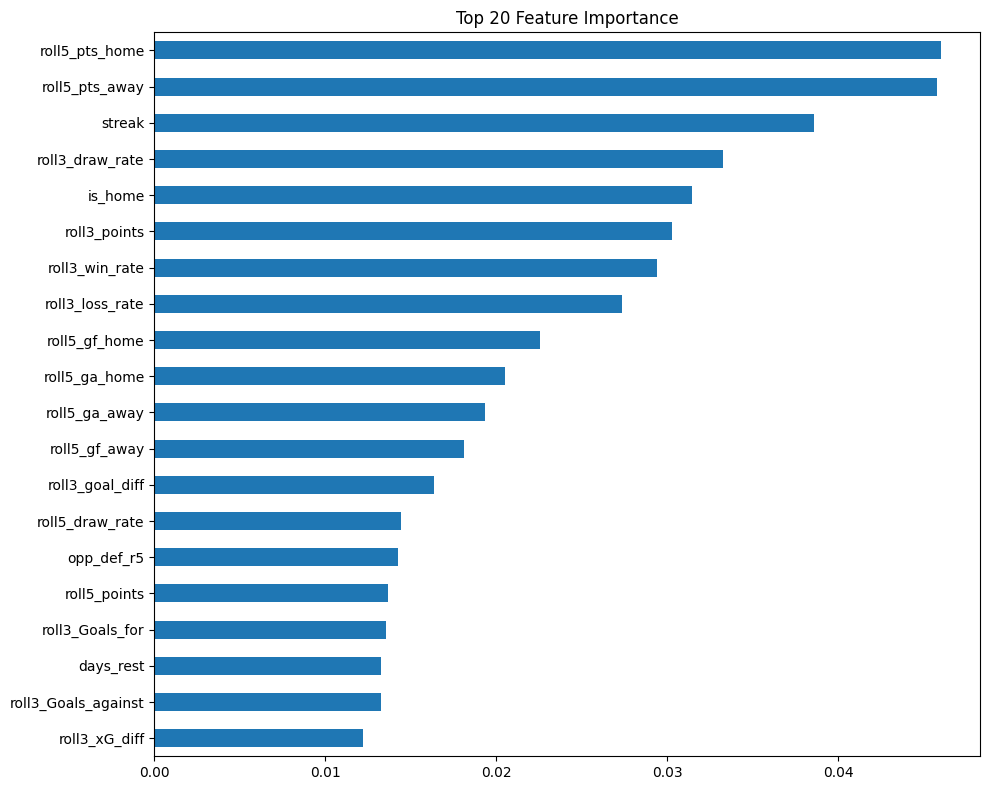

In [47]:
imp = pd.Series(final_model.feature_importances_, index=feat_cols).sort_values(ascending=False)
print("\n[IMPORTANCE] Top 20 features:")
print(imp.head(20).to_string())

# Optional: bar chart (quick)
imp.head(20).plot(kind="barh", figsize=(10, 8), title="Top 20 Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

Confusion matrix (rows = Actual, cols = Predicted):
[[7253  786  883]
 [ 501 4855  618]
 [ 964  739 7239]]


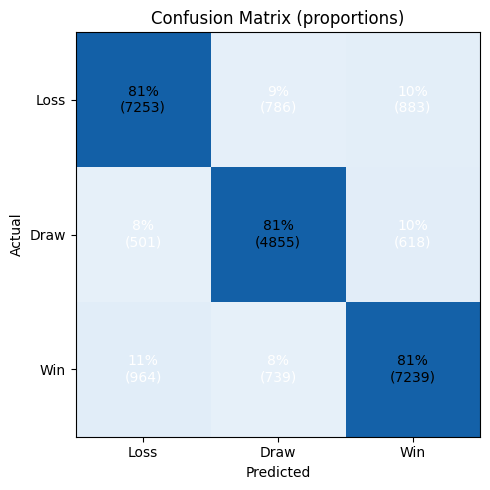

In [48]:
# Predict on all data for evaluation
preds_all = final_model.predict(X)
proba_all = final_model.predict_proba(X)   # if needed later

cm = confusion_matrix(y, preds_all)
cm_pct = cm / cm.sum(axis=1, keepdims=True)

print("Confusion matrix (rows = Actual, cols = Predicted):")
print(cm)

# Quick visual
plt.figure(figsize=(6,5))
plt.imshow(cm_pct, cmap="Blues", vmin=0, vmax=1)
plt.xticks([0,1,2], list(LABEL_NAMES.values()))
plt.yticks([0,1,2], list(LABEL_NAMES.values()))
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix (proportions)")
for i in range(3):
    for j in range(3):
        plt.text(j, i, f"{cm_pct[i,j]:.0%}\n({cm[i,j]})",
                 ha="center", va="center",
                 color="white" if cm_pct[i,j] < 0.6 else "black")
plt.tight_layout()
plt.show()